# Exercício 3 · Padronização e Escalonamento
**Ciência de Dados — Preparação dos Dados (CRISP-DM)**
**Aluno(a):** ____________________

**Base:** Adult Census Income (UCI). Usei os dois arquivos da UCI: `adult.data` (32.561 pessoas, que tratei como **treino**) e `adult.test` (16.281 pessoas, **teste**). A documentação está em `adult.names`.

**Contexto:** a base tem fama de "limpa", mas esconde problemas de texto e de valores ausentes. Depois de corrigir isso, preparo as colunas numéricas para modelos que dependem de escala.

In [1]:
# IMPORTAÇÕES
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

pd.options.display.float_format = '{:,.3f}'.format
pd.options.display.width = 150

In [2]:
# NOMES DAS COLUNAS (consulte a documentação do dataset)
# Em vez de digitar, leio do próprio adult.names: cada atributo aparece numa linha "nome: valores."
with open('adult.names', encoding='utf-8') as f:
    linhas_doc = [l.strip() for l in f if re.match(r'^[a-z-]+: ', l)]

documentacao = {l.split(':')[0]: l.split(':', 1)[1].strip().rstrip('.') for l in linhas_doc}
colunas = list(documentacao) + ['income']          # a classe (>50K / <=50K) é descrita à parte no arquivo
print(len(colunas), 'colunas:', colunas)

15 colunas: ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']


In [3]:
# CARREGAMENTO DOS DADOS
treino = pd.read_csv('adult.data', header=None, names=colunas)
teste = pd.read_csv('adult.test', header=None, names=colunas, skiprows=1)   # 1ª linha do teste é um comentário ("|1x3 Cross validator")

df = pd.concat([treino.assign(origem='treino'), teste.assign(origem='teste')], ignore_index=True)
print('treino:', treino.shape, '| teste:', teste.shape, '| juntos:', df.shape)
print('Nulos segundo o pandas:', df.isna().sum().sum())
df.head()

treino: (32561, 15) | teste: (16281, 15) | juntos: (48842, 16)
Nulos segundo o pandas: 0


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income,origem
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,treino
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,treino
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,treino
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,treino
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,treino


O pandas diz que **não há nenhum nulo**. Antes de acreditar nisso, vou olhar os textos de perto.

In [4]:
# INSPEÇÃO DAS COLUNAS CATEGÓRICAS
categoricas = [c for c in colunas if df[c].dtype == object or pd.api.types.is_string_dtype(df[c])]

def inspecionar(base):
    linhas = []
    for c in categoricas:
        s = base[c]
        linhas.append({
            'coluna': c,
            'distintos': s.nunique(),
            'com espaço nas pontas': (s != s.str.strip()).sum(),
            'distintos sem espaço': s.str.strip().nunique(),
            'distintos sem espaço e minúsculo': s.str.strip().str.lower().nunique(),
            "valores '?'": (s.str.strip() == '?').sum(),
        })
    return pd.DataFrame(linhas).set_index('coluna')

inspecionar(df)

,distintos,com espaço nas pontas,distintos sem espaço,distintos sem espaço e minúsculo,valores '?'
coluna,,,,,
workclass,9,48842,9,9,2799
education,16,48842,16,16,0
marital-status,7,48842,7,7,0
occupation,15,48842,15,15,2809
relationship,6,48842,6,6,0
race,5,48842,5,5,0
sex,2,48842,2,2,0
native-country,42,48842,42,42,857
income,4,48842,4,4,0


In [5]:
# income tem 4 categorias, mas deveria ter 2. Olhando por arquivo de origem:
print(df.groupby('origem')['income'].value_counts().to_string())

# Os valores existem na documentação? (comparo com a lista oficial do adult.names)
print()
for c in ['workclass', 'occupation', 'native-country']:
    oficiais = {v.strip() for v in documentacao[c].split(',')}
    fora = sorted(set(df[c].str.strip()) - oficiais)
    print(f'{c}: valores que não estão na documentação -> {fora}')

origem  income
teste   <=50K.    12435
        >50K.      3846
treino  <=50K     24720
        >50K       7841

workclass: valores que não estão na documentação -> ['?']
occupation: valores que não estão na documentação -> ['?']
native-country: valores que não estão na documentação -> ['?']


**O que a inspeção revelou**
- **(a) Espaços extras:** todas as colunas de texto começam com um espaço (`' Private'`, `' Male'`). O número de categorias não muda ao tirar o espaço, porque ele está em *todos* os valores, mas um filtro como `df['sex'] == 'Male'` retorna **zero linhas**.
- **(b) Grafia diferente para a mesma categoria:** não há diferença de maiúscula/minúscula. Mas `income` tem **4 valores em vez de 2**: no arquivo de teste a classe vem com **ponto final** (`'>50K.'`, `'<=50K.'`). Para o pandas, `'>50K'` e `'>50K.'` são classes diferentes. Um modelo treinado no `adult.data` e avaliado no `adult.test` erraria 100% das previsões só por isso.
- **(c) Marcador de desconhecido:** `?` aparece em `workclass`, `occupation` e `native-country`. Ele **não está na lista de valores** do `adult.names`, ou seja, não é uma categoria: é a forma que o censo usou para "não informado".

In [6]:
# PADRONIZAÇÃO DOS TEXTOS (ANTES x DEPOIS)
def padronizar(base):
    base = base.copy()
    for c in categoricas:
        base[c] = (base[c].str.strip()                        # tira espaços das pontas
                          .str.replace(r'\s+', ' ', regex=True)  # espaços repetidos no meio
                          .str.rstrip('.'))                    # ponto final do adult.test ('>50K.' -> '>50K')
    return base

df_pad = padronizar(df)

comparativo = pd.DataFrame({
    'categorias antes': df[categoricas].nunique(),
    'categorias depois': df_pad[categoricas].nunique(),
    'valores com espaço antes': (df[categoricas] != df[categoricas].apply(lambda s: s.str.strip())).sum(),
    'valores com espaço depois': (df_pad[categoricas] != df_pad[categoricas].apply(lambda s: s.str.strip())).sum(),
})
comparativo

,categorias antes,categorias depois,valores com espaço antes,valores com espaço depois
workclass,9,9,48842,0
education,16,16,48842,0
marital-status,7,7,48842,0
occupation,15,15,48842,0
relationship,6,6,48842,0
race,5,5,48842,0
sex,2,2,48842,0
native-country,42,42,48842,0
income,4,2,48842,0


In [7]:
# Testes rápidos de que a padronização funcionou
print("Filtro sex == 'Male'      antes:", (df['sex'] == 'Male').sum(), '| depois:', (df_pad['sex'] == 'Male').sum())
print('Classes de income depois :', df_pad['income'].value_counts().to_dict())
print('% com renda >50K por arquivo:')
print((df_pad.groupby('origem')['income'].apply(lambda s: (s == '>50K').mean() * 100)).round(2).to_string())

Filtro sex == 'Male'      antes: 0 | depois: 32650
Classes de income depois : {'<=50K': 37155, '>50K': 11687}
% com renda >50K por arquivo:
origem
teste    23.620
treino   24.080


**Resultado da padronização:** a única coluna em que o **número de categorias** muda é `income` (4 → 2), por causa do ponto final. Nas outras, o número é o mesmo, mas os **48.842 valores com espaço** de cada coluna (todos) passam a zero, e o filtro `sex == 'Male'` volta a funcionar. A proporção de renda >50K fica parecida nos dois arquivos (cerca de 24%), o que confirma que agora treino e teste falam a mesma língua.

In [8]:
# CONVERSÃO DOS MARCADORES DE AUSÊNCIA
df_nan = df_pad.replace('?', np.nan)

surgiram = pd.DataFrame({
    'nulos antes': df_pad.isna().sum(),
    'nulos depois': df_nan.isna().sum(),
})
surgiram['apareceram'] = surgiram['nulos depois'] - surgiram['nulos antes']
surgiram['% da coluna'] = surgiram['apareceram'] / len(df_nan) * 100
surgiram = surgiram[surgiram['apareceram'] > 0]
display(surgiram)

print('Total de nulos escondidos:', surgiram['apareceram'].sum())
print('Pessoas com pelo menos um nulo:', df_nan.isna().any(axis=1).sum(), f'({df_nan.isna().any(axis=1).mean() * 100:.1f}%)')

# quem não tem workclass também não tem occupation?
sem_wc = df_nan['workclass'].isna()
print(f"Sem workclass: {sem_wc.sum()} | desses, também sem occupation: {df_nan.loc[sem_wc, 'occupation'].isna().sum()}")
print("workclass = 'Never-worked' (nunca trabalhou) e occupation nula:",
      (df_nan['workclass'].eq('Never-worked') & df_nan['occupation'].isna()).sum())

,nulos antes,nulos depois,apareceram,% da coluna
workclass,0,2799,2799,5.731
occupation,0,2809,2809,5.751
native-country,0,857,857,1.755


Total de nulos escondidos: 6465
Pessoas com pelo menos um nulo: 3620 (7.4%)
Sem workclass: 2799 | desses, também sem occupation: 2799
workclass = 'Never-worked' (nunca trabalhou) e occupation nula: 10


In [9]:
# Outro tipo de "marcador": valores-teto nas colunas numéricas (registro apenas; não viram NaN)
tetos = pd.DataFrame({
    'valor máximo': treino[['age', 'capital-gain', 'hours-per-week']].max(),
    'qtd. de pessoas no máximo': [(treino[c] == treino[c].max()).sum() for c in ['age', 'capital-gain', 'hours-per-week']],
    'segundo maior valor': [treino.loc[treino[c] < treino[c].max(), c].max() for c in ['age', 'capital-gain', 'hours-per-week']],
})
tetos

,valor máximo,qtd. de pessoas no máximo,segundo maior valor
age,90,43,88
capital-gain,99999,159,41310
hours-per-week,99,85,98


**Ausentes que apareceram:** `workclass` (2.799), `occupation` (2.809) e `native-country` (857), somando **6.465 valores** que o `isna()` não via. **Todas** as 2.799 pessoas sem `workclass` também estão sem `occupation`: é quem não respondeu a parte sobre trabalho. Os 10 nulos a mais em `occupation` são de pessoas com `workclass = Never-worked` (nunca trabalharam), para quem a ocupação realmente não existe. Nesses 10 casos, "nulo" significa **não se aplica**, e não "não informado".

**Valores-teto:** `capital-gain` tem 159 pessoas com exatamente **99.999** e o segundo maior valor é 41.310. Isso indica um **código de teto** ("99.999 ou mais"), não um valor medido. O mesmo vale, em menor grau, para `age = 90` e `hours-per-week = 99`. Não converti para `NaN`, porque o valor não é desconhecido (sabemos que é alto), mas isso influencia o escalonamento logo abaixo.

## Escalonamento
**Como fiz:** o escalonador aprende os parâmetros (mínimo, máximo, média, desvio, mediana, IQR) **só com o treino** e depois aplica os mesmos parâmetros no teste. Se eu ajustasse com tudo junto, informações do teste "vazariam" para o treino.

Para entender de verdade o que cada técnica faz, calculo a fórmula **na mão** e confiro se dá o mesmo resultado do scikit-learn.

In [10]:
# Colunas numéricas (fnlwgt entra para comparação — ver reflexão 3)
numericas = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
X_treino = df_nan.loc[df_nan['origem'] == 'treino', numericas]
X_teste = df_nan.loc[df_nan['origem'] == 'teste', numericas]

def resumo(X):
    return X.agg(['min', 'max', 'mean', 'std']).T

print('Colunas originais (treino)')
resumo(X_treino)

Colunas originais (treino)


,min,max,mean,std
age,17.000,90.000,38.582,13.640
fnlwgt,"12,285.000","1,484,705.000","189,778.367","105,549.978"
education-num,1.000,16.000,10.081,2.573
capital-gain,0.000,"99,999.000","1,077.649","7,385.292"
capital-loss,0.000,"4,356.000",87.304,402.960
hours-per-week,1.000,99.000,40.437,12.347


In [11]:
# ESCALONAMENTO — MIN-MAX
# fórmula: (x - mín) / (máx - mín)
minmax = MinMaxScaler().fit(X_treino)
mm_treino = pd.DataFrame(minmax.transform(X_treino), columns=numericas)
mm_teste = pd.DataFrame(minmax.transform(X_teste), columns=numericas)

manual = (X_treino - X_treino.min()) / (X_treino.max() - X_treino.min())
print('Fórmula manual == scikit-learn?', np.allclose(manual.values, mm_treino.values))
print('Valores do TESTE fora de [0, 1]:', int(((mm_teste < 0) | (mm_teste > 1)).sum().sum()))
resumo(mm_treino)

Fórmula manual == scikit-learn? True


Valores do TESTE fora de [0, 1]: 1


,min,max,mean,std
age,0.000,1.000,0.296,0.187
fnlwgt,0.000,1.000,0.121,0.072
education-num,0.000,1.000,0.605,0.172
capital-gain,0.000,1.000,0.011,0.074
capital-loss,0.000,1.000,0.020,0.093
hours-per-week,0.000,1.000,0.402,0.126


In [12]:
# ESCALONAMENTO — Z-SCORE
# fórmula: (x - média) / desvio-padrão
zscore = StandardScaler().fit(X_treino)
z_treino = pd.DataFrame(zscore.transform(X_treino), columns=numericas)
z_teste = pd.DataFrame(zscore.transform(X_teste), columns=numericas)

manual = (X_treino - X_treino.mean()) / X_treino.std(ddof=0)      # o scikit-learn usa o desvio populacional
print('Fórmula manual == scikit-learn?', np.allclose(manual.values, z_treino.values))
resumo(z_treino)

Fórmula manual == scikit-learn? True


,min,max,mean,std
age,-1.582,3.770,-0.000,1.000
fnlwgt,-1.682,12.269,-0.000,1.000
education-num,-3.530,2.301,0.000,1.000
capital-gain,-0.146,13.395,0.000,1.000
capital-loss,-0.217,10.594,-0.000,1.000
hours-per-week,-3.194,4.743,-0.000,1.000


In [13]:
# ESCALONAMENTO — ROBUSTO
# fórmula: (x - mediana) / IQR, com IQR = Q3 - Q1
robusto = RobustScaler().fit(X_treino)
r_treino = pd.DataFrame(robusto.transform(X_treino), columns=numericas)
r_teste = pd.DataFrame(robusto.transform(X_teste), columns=numericas)

iqr = X_treino.quantile(0.75) - X_treino.quantile(0.25)
print(pd.DataFrame({'mediana': X_treino.median(), 'IQR calculado': iqr, 'escala usada pelo sklearn': robusto.scale_}).to_string())
iqr_seguro = iqr.replace(0, 1)                                     # o sklearn troca IQR = 0 por 1
manual = (X_treino - X_treino.median()) / iqr_seguro
print('\nFórmula manual == scikit-learn?', np.allclose(manual.values, r_treino.values))
resumo(r_treino)

                   mediana  IQR calculado  escala usada pelo sklearn
age                 37.000         20.000                     20.000
fnlwgt         178,356.000    119,224.000                119,224.000
education-num       10.000          3.000                      3.000
capital-gain         0.000          0.000                      1.000
capital-loss         0.000          0.000                      1.000
hours-per-week      40.000          5.000                      5.000

Fórmula manual == scikit-learn? True


,min,max,mean,std
age,-1.000,2.650,0.079,0.682
fnlwgt,-1.393,10.957,0.096,0.885
education-num,-3.000,2.000,0.027,0.858
capital-gain,0.000,"99,999.000","1,077.649","7,385.292"
capital-loss,0.000,"4,356.000",87.304,402.960
hours-per-week,-7.800,11.800,0.087,2.469


In [14]:
# COMPARAÇÃO ENTRE AS TÉCNICAS
comparacao = pd.concat({
    'original': resumo(X_treino),
    'Min-Max': resumo(mm_treino),
    'Z-score': resumo(z_treino),
    'Robusto': resumo(r_treino),
}, axis=1).round(2)
comparacao

original                                       Min-Max                   Z-score                     Robusto                       \
                      min           max        mean         std     min   max  mean   std     min    max   mean   std     min        max      mean   
age                17.000        90.000      38.580      13.640   0.000 1.000 0.300 0.190  -1.580  3.770 -0.000 1.000  -1.000      2.650     0.080   
fnlwgt         12,285.000 1,484,705.000 189,778.370 105,549.980   0.000 1.000 0.120 0.070  -1.680 12.270 -0.000 1.000  -1.390     10.960     0.100   
education-num       1.000        16.000      10.080       2.570   0.000 1.000 0.610 0.170  -3.530  2.300  0.000 1.000  -3.000      2.000     0.030   
capital-gain        0.000    99,999.000   1,077.650   7,385.290   0.000 1.000 0.010 0.070  -0.150 13.390  0.000 1.000   0.000 99,999.000 1,077.650   
capital-loss        0.000     4,356.000      87.300     402.960   0.000 1.000 0.020 0.090  -0.220 10.590 -0.000 1.000   0.000  4,356.000    87.300   
hours-per-week      1.000        99.000      40.440      12.350   0.000 1.000 0.400 0.130  -3.190  4.740 -0.000 1.000  -7.800     11.800     0.090   

                          
                     std  
age                0.680  
fnlwgt             0.890  
education-num      0.860  
capital-gain   7,385.290  
capital-loss     402.960  
hours-per-week     2.470

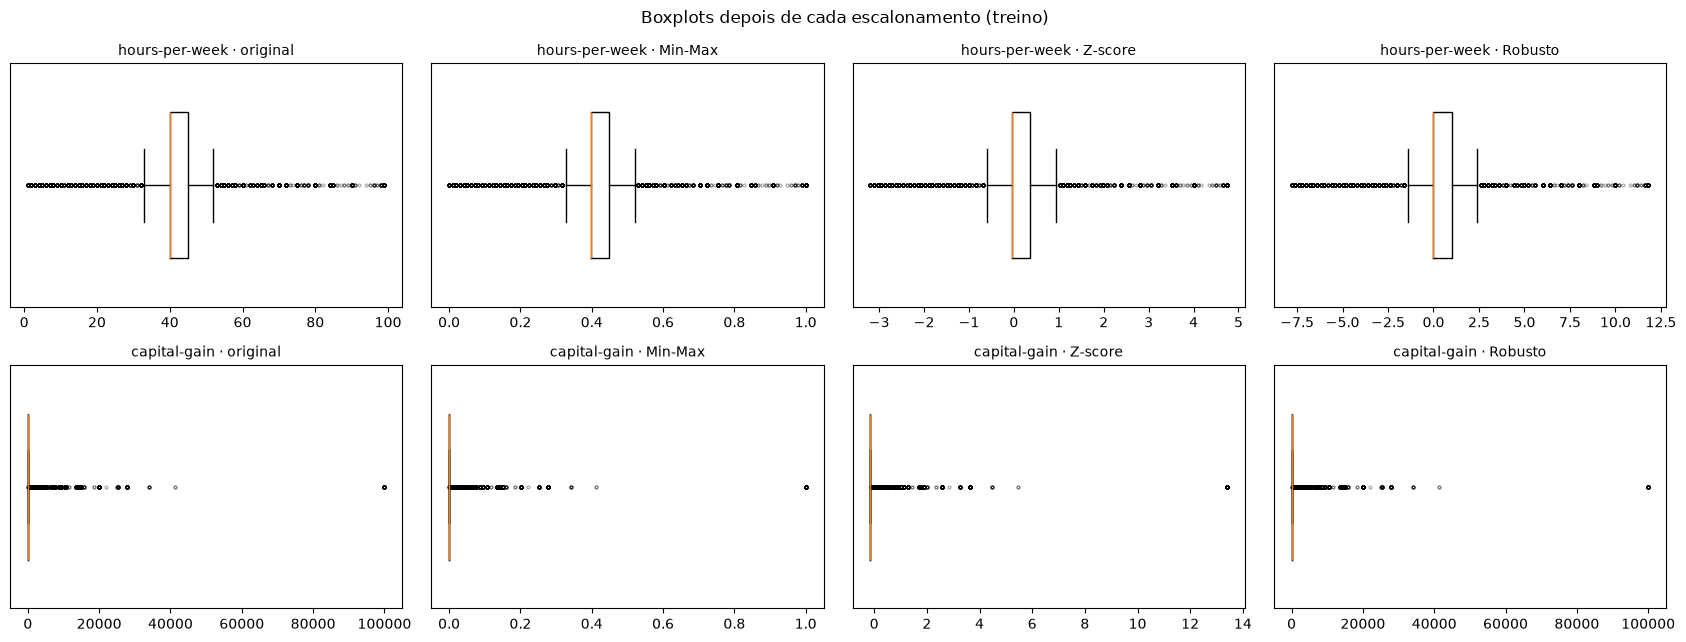

In [15]:
# Visualização: mesma coluna, quatro escalas. Coluna "comportada" (hours-per-week) x coluna com extremos (capital-gain)
versoes = {'original': X_treino.reset_index(drop=True), 'Min-Max': mm_treino, 'Z-score': z_treino, 'Robusto': r_treino}
fig, axes = plt.subplots(2, 4, figsize=(17, 6.5))
for linha, col in enumerate(['hours-per-week', 'capital-gain']):
    for ax, (nome, dados) in zip(axes[linha], versoes.items()):
        ax.boxplot(dados[col], orientation='horizontal', widths=0.6, flierprops={'markersize': 2, 'alpha': 0.3})
        ax.set_title(f'{col} · {nome}', fontsize=10)
        ax.set_yticks([])
plt.suptitle('Boxplots depois de cada escalonamento (treino)')
plt.tight_layout()
plt.show()

In [16]:
# Números que resumem o problema de capital-gain
cg = X_treino['capital-gain'].reset_index(drop=True)
print(f'Zeros em capital-gain: {(cg == 0).mean() * 100:.1f}% | em capital-loss: {(X_treino["capital-loss"] == 0).mean() * 100:.1f}%')
print(f'Min-Max : metade de cima da escala (0,5 a 1) tem {(mm_treino["capital-gain"] > 0.5).sum()} pessoas, todas com 99.999')
print(f'Min-Max : {(mm_treino["capital-gain"] < 0.01).mean() * 100:.1f}% das pessoas ficam abaixo de 0,01')
print(f'Z-score : o zero vira {z_treino["capital-gain"][cg == 0].iloc[0]:.3f} e o 99.999 vira {z_treino["capital-gain"].max():.2f}')
print(f'Robusto : IQR = {iqr["capital-gain"]:.0f} -> valores iguais aos originais? {np.allclose(r_treino["capital-gain"], cg)}')

# E se eu tirar o log antes?
log_cg = np.log1p(X_treino[['capital-gain']])
print(f'Com log1p antes do Min-Max, o maior valor diferente do teto passa a ficar em '
      f'{MinMaxScaler().fit_transform(log_cg)[(cg < 99999).values].max():.2f} (antes: {mm_treino["capital-gain"][cg < 99999].max():.2f})')

Zeros em capital-gain: 91.7% | em capital-loss: 95.3%
Min-Max : metade de cima da escala (0,5 a 1) tem 159 pessoas, todas com 99.999
Min-Max : 91.8% das pessoas ficam abaixo de 0,01
Z-score : o zero vira -0.146 e o 99.999 vira 13.39
Robusto : IQR = 0 -> valores iguais aos originais? True
Com log1p antes do Min-Max, o maior valor diferente do teto passa a ficar em 0.92 (antes: 0.41)


**Leitura da comparação**
- **Min-Max:** todas as colunas vão para [0, 1] no treino, mas a régua é definida pelos dois extremos. Em `hours-per-week` funciona bem. Em `capital-gain`, como o máximo é o teto 99.999, quase todo mundo fica espremido perto de 0 e a metade de cima da escala é ocupada apenas pelas pessoas no teto. No **teste** apareceu 1 valor fora de [0, 1]: isso acontece sempre que alguém do teste passa do mínimo ou do máximo visto no treino, e é esperado.
- **Z-score:** média 0 e desvio 1 em todas as colunas (confere com a tabela). Em `age` e `hours-per-week` os valores ficam numa faixa razoável. Em `capital-gain`, a média e o desvio são calculados com os extremos dentro, então o 99.999 vira mais de 13 desvios, um número que não significa "raro" de verdade.
- **Robusto:** usa mediana e IQR, então os extremos não afetam a régua. Funciona bem em `age` e `fnlwgt`. Em `hours-per-week`, como metade das pessoas trabalha entre 40 e 45 horas, o IQR é só 5 e os valores vão de -7,8 a 11,8 (não há problema nisso, só mostra que a régua é a "pessoa típica"). Mas em `capital-gain` e `capital-loss` mais de 75% dos valores são zero, então **Q1 = Q3 = 0 e o IQR é 0**. Como não dá para dividir por zero, o scikit-learn usa 1 como escala e a coluna **sai exatamente igual à original**.
- **Saída possível:** aplicar `log1p` antes de escalonar espalha melhor os valores intermediários: com o log, o maior ganho abaixo do teto passa de 0,41 para 0,92 na escala Min-Max. Outra opção é trocar a coluna por "teve ganho de capital? sim/não".

## Respostas às perguntas de reflexão

**1. Por que `df.isna().sum()` pode retornar zero em todas as colunas de um dataset que tem dados faltando?**
Porque o `isna()` só reconhece o "vazio oficial" do pandas (`NaN`, `None`, `NaT`, célula vazia no CSV). Se quem montou a base usou um código próprio para "não sei", como `?`, `-`, `N/A`, `999` ou `"desconhecido"`, o pandas lê como um texto ou número qualquer. No Adult, o `isna()` dava 0 e havia **6.465** valores faltando atrás de `?`. A forma de achar é olhar os valores de cada coluna (`value_counts`, `unique`) e conferir com a documentação: o `?` nem aparece na lista oficial de categorias do `adult.names`. A correção é `replace('?', np.nan)` ou, já na leitura, `na_values='?'` com `skipinitialspace=True`.

**2. Em `capital-gain` a maioria dos valores é zero. Qual técnica é mais afetada? Justifique.**
O **escalonamento robusto** é o mais afetado. Ele depende do IQR, e com mais de 90% de zeros o primeiro e o terceiro quartil são ambos 0. O IQR vira 0, o scikit-learn usa escala 1 e a coluna **não é escalonada**: o resultado é idêntico ao original, com valores até 99.999, enquanto as outras colunas ficam na casa das unidades. Justamente a técnica feita para resistir a extremos fica sem efeito. O **Min-Max** vem logo atrás: ele escala, mas a régua fica tão esticada pelo teto que quase todo mundo vai parar perto de 0. O **Z-score** é o que menos quebra, mas ainda gera valores de mais de 13 desvios. Nenhuma das três resolve sozinha: o melhor é transformar antes (log) ou criar uma variável binária.

**3. Faz sentido escalonar todas as colunas numéricas? O que é `fnlwgt`?**
Não. O `fnlwgt` (*final weight*) é um **peso amostral** calculado pelo Census Bureau: ele diz quantas pessoas da população americana aquela linha representa, a partir de idade, raça, sexo e estado. Ele descreve **como a amostra foi montada**, não uma característica da pessoa. Usá-lo como variável de entrada num modelo, escalonado ou não, faz o modelo aprender algo sobre o desenho do censo. O uso correto é como **peso das observações** (`sample_weight`) em estatísticas e no treino, ou simplesmente deixá-lo de fora. Além disso:
- `education-num` é a versão numérica de `education`; escalonar as duas é guardar a mesma informação duas vezes;
- modelos de árvore (árvore de decisão, random forest) **não precisam** de escalonamento; ele faz diferença para KNN, SVM, regressões com regularização e redes neurais;
- variáveis com teto ou muitos zeros (`capital-gain`, `capital-loss`) pedem transformação antes do escalonamento.